In [1]:
from sklearn.feature_extraction.text import TfidfVectorizer

corpus = ["advanced neural network process text", "the dog at the food"]
vectorizer = TfidfVectorizer()
vectorizer.fit(corpus) # NO training occurs here. Just counting

# The "learned parameters" are just dictionary and a static array
print(vectorizer.vocabulary_)

print(vectorizer.idf_)


{'advanced': 0, 'neural': 5, 'network': 4, 'process': 6, 'text': 7, 'the': 8, 'dog': 2, 'at': 1, 'food': 3}
[1.40546511 1.40546511 1.40546511 1.40546511 1.40546511 1.40546511
 1.40546511 1.40546511 1.40546511]


In [2]:
sort(vectorizer.vocabulary_)

NameError: name 'sort' is not defined

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

# Our historical constraint: A small, text-based corpus
corpus = [
    "the dog chased the cat",                  # Doc 0
    "the dog ate the food",                    # Doc 1
    "advanced neural networks process text"    # Doc 2
]

# Initialize the vectorizer. 
# Note: sklearn applies L2 normalization by default to prevent long-document bias 
# and adds '1' to the IDF formula to prevent zero-division (smoothing).
vectorizer = TfidfVectorizer()

# Fit the vocabulary and transform documents into a sparse matrix
tfidf_matrix = vectorizer.fit_transform(corpus)

# Extract feature names (the vocabulary) to map columns to words
feature_names = vectorizer.get_feature_names_out()

# Convert the sparse matrix to a dense DataFrame for visibility
df_tfidf = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)

print("TF-IDF Weights for Document 0 ('the dog chased the cat'):")
# Transpose and filter for non-zero weights in Doc 0
doc_0_weights = df_tfidf.iloc[0][df_tfidf.iloc[0] > 0].sort_values(ascending=False)
print(doc_0_weights)

"""
Expected Output Intuition:
'cat' and 'chased' will have the highest weights because they are unique to Doc 0.
'dog' will have a moderate weight (appears in Doc 0 and Doc 1).
'the' will have the lowest non-zero weight (appears heavily, but exists in multiple docs).
Words like 'neural' and 'networks' will be 0.0, as they don't appear in Doc 0.
"""

TF-IDF Weights for Document 0 ('the dog chased the cat'):
the       0.687703
cat       0.452123
chased    0.452123
dog       0.343851
Name: 0, dtype: float64


"\nExpected Output Intuition:\n'cat' and 'chased' will have the highest weights because they are unique to Doc 0.\n'dog' will have a moderate weight (appears in Doc 0 and Doc 1).\n'the' will have the lowest non-zero weight (appears heavily, but exists in multiple docs).\nWords like 'neural' and 'networks' will be 0.0, as they don't appear in Doc 0.\n"

Approach 1: Low-level 'transformers' + Manual PyTorch Steps


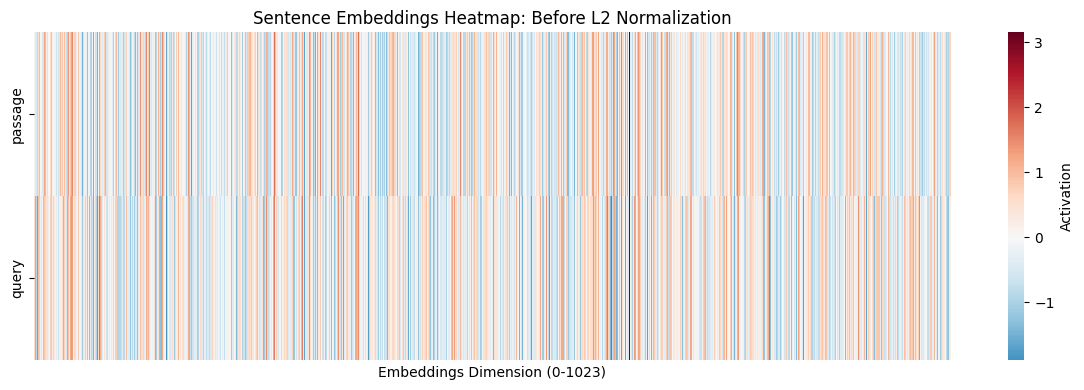

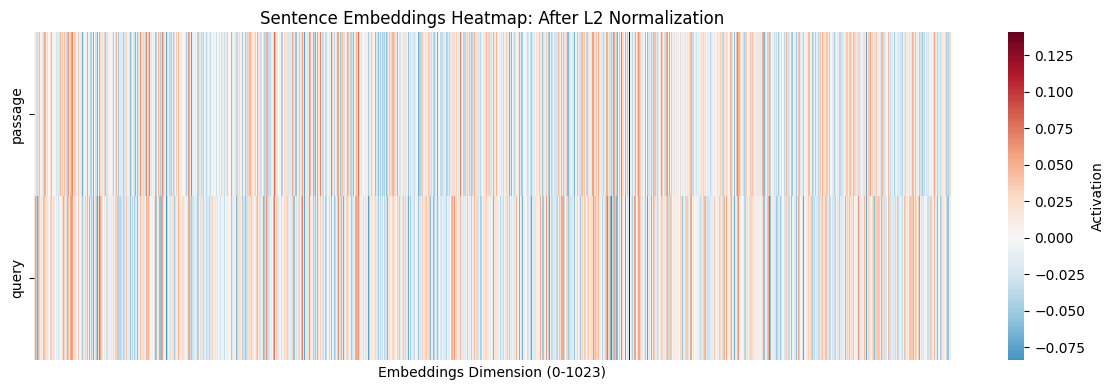

Token embeddings shape (Matrix) : torch.Size([2, 20, 1024])
Pooled sentence embeddings shape: torch.Size([2, 1024])
PyTorch Cosine Similarity       : 0.8444



In [21]:
# Word Embedding vs Sentence Embedding

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import AutoModel, AutoTokenizer
from sentence_transformers import SentenceTransformer

# Shared Input (Note the required 'passage:' and 'query:' prefixes for E5)
passage_text = "passage: Retrieval-Augmented Generation (RAG) relies on dense vector embeddings."
query_text = "query: How does RAG handle text representation?"

texts = [passage_text, query_text]

print("=" * 60)
print("Approach 1: Low-level 'transformers' + Manual PyTorch Steps")
print("=" * 60)

# 1. Initialize E5-Large-V2
model_id = 'intfloat/e5-large-v2'
tokenizer = AutoTokenizer.from_pretrained(model_id)
model = AutoModel.from_pretrained(model_id)

# 2. Tokenization E5-Large-V2
batch_dict = tokenizer(
    texts,
    max_length=512,
    padding=True,
    truncation=True,
    return_tensors='pt'
)

with torch.no_grad():
    # 3. Contextualization (Foward Pass)
    # token_embeddings shape: (batch_size, sequence_length, hidden_size)
    outputs = model(**batch_dict)
    token_embeddings = outputs.last_hidden_state # (2, 14, 1024)

# 4. Manual Mean Pooling (Squashing Tokens -> Sentence vector)
attention_mask = batch_dict['attention_mask'] # shape: (2, 14)

# Expand mask to match embedding dimensions (2, 14, 1024)
input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()

# Multiply zeros out all [PAD] token embeddings, then sum across the token dimension (dim=1).
sum_embeddings = torch.sum(token_embeddings * input_mask_expanded, dim=1)

# Count the number of real (non-padding) tokens per sentence for the denominator.
# clamp(min=1e-9) prevents division-by-zero if a sequence were entirely padding.
# Result shape: (2, 1024)
sum_mask = torch.clamp(input_mask_expanded.sum(dim=1), min=1e-9)

# Divide sum by count -> true mean over real tokens only. Shape: (2, 1024)
sentence_embeddings_torch = sum_embeddings / sum_mask

plt.figure(figsize=(12, 4))
sns.heatmap(
    sentence_embeddings_torch.cpu().numpy(),
    cmap='RdBu_r',
    center=0,
    yticklabels=['passage', 'query'],
    xticklabels=False,
    cbar_kws={'label':'Activation'}
)
plt.xlabel('Embeddings Dimension (0-1023)')
plt.title('Sentence Embeddings Heatmap: Before L2 Normalization')
plt.tight_layout()
plt.show()


# 5. L2 Normalization
# Divides each 1024-dim vector by its own mangnitude so ||v||=1.
# After this, dot product == cosine similarity (no magnitude bias).
# E5 models are specifically trained to be used with normalized embeddings.
sentence_embeddings_torch = F.normalize(sentence_embeddings_torch, p=2, dim=1)

# Heatmap Plot
plt.figure(figsize=(12, 4))
sns.heatmap(
    sentence_embeddings_torch.cpu().numpy(),
    cmap='RdBu_r',
    center=0,
    yticklabels=['passage', 'query'],
    xticklabels=False,
    cbar_kws={'label':'Activation'}
)
plt.xlabel('Embeddings Dimension (0-1023)')
plt.title('Sentence Embeddings Heatmap: After L2 Normalization')
plt.tight_layout()
plt.show()

# 6. Compute Cosine Similarity via Dot Product
# texts[0]=passage, texts[1]=query → embeddings at indices 0 and 1 respectively.
# unsqueeze(0) reshapes from (1024,) → (1, 1024) so torch.mm (matrix multiply) works.
query_vector_torch = sentence_embeddings_torch[1].unsqueeze(0)      # (1, 1024)
passage_vector_torch = sentence_embeddings_torch[0].unsqueeze(0)    # (1, 1024)

# torch.mm does (1, 1024) @ (1024, 1) -> scalar in a (1,1) tensor.
# Because both vectors are L2-normalized, this equals cosine similarity.
similarity_score_torch = torch.mm(query_vector_torch, passage_vector_torch.transpose(0, 1))

print(f"Token embeddings shape (Matrix) : {token_embeddings.shape}")
print(f"Pooled sentence embeddings shape: {sentence_embeddings_torch.shape}")
print(f"PyTorch Cosine Similarity       : {similarity_score_torch.item():.4f}\n")

In [22]:
# ----------------------------------------------------------------------
# Approach 2: High-Lebel 'sentence-transformers' Wrapper
# ----------------------------------------------------------------------

# Loads the model with itys pooling and normalization config pre-configured
# Internally does everythingh in Approach 1 automatically
st_model = SentenceTransformer('intfloat/e5-large-v2')

# encode() runs the tokenization -> forward pass -> mean pooling -> L2 normalization in one call.
# Returns a NumPy array of shape (2, 1024)
embeddings_np = st_model.encode(texts)

# np.dot on two 1D unit vectors == cosine similarity.
# embeddings_np[1] = query, embeddings_np[0] = passage
similarity_score_np = np.dot(embeddings_np[1], embeddings_np[0])

print(f"Similarity Score: {similarity_score_np}")



huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Similarity Score: 0.8443524241447449


In [ ]:
from openai import OpenAI
client = OpenAI(
    api_key="rsainju", # Your username, not an API key
    base_url="https://apps.inside.anl.gov/argoapi/v1"
)

In [3]:
# Try calling openai GPT5.4
prompt = (
    f"You are an expert intelligence analyst.\n"
    f"Analyze the following knowledge graph community containing these entities:\n"
    f"Relationships:\nAA --> BB\n\n"
    f"Write a concise, 3-sentence summary of the overarching theme and key dynamics of this cluster."
)


# 3.Invoke GPT-5.4 via the Chat Completions API
response = client.chat.completions.create(
    model="gpt54",
    messages=[
        {"role": "system", "comtent": "You synthesize graph topology into dense, actionable reports."},
        {"role": "user", "content": prompt}
    ],
    temperature=0.2, # Low temperature forces deterministic, factual extraction
    max_tokens=150
)

In [7]:
response.choices[0].message.content

'This cluster is extremely sparse, containing only a single directed relationship from AA to BB. The overarching theme is therefore limited to a basic linkage or influence pathway in which AA is positioned as the source and BB as the target. With no additional entities or contextual ties, the key dynamic is simply a one-step connection whose meaning depends entirely on what AA and BB represent.'

In [11]:
# ======================================================================
# §0 — GraphRAG implementation
# ======================================================================
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from cdlib import algorithms


In [12]:
# ----------------------------------------------------------------------
# Implementing the MicroGraphRAG
# ----------------------------------------------------------------------

class MicroGraphRAG:
    def __init__(self) -> None:
        # 1. Initialize the Knowledge Graph
        self.G = nx.Graph()
        self.communities = []
        self.community_reports = {}

    def extract_and_build_graph(self, simulated_triplets):
        """
        In production, an LLM extracts these triplets from raw text via NER.
        We simulate the extracted triplets here to build the graph structure.
        """
        for source, relation, target in simulated_triplets:
            self.G.add_edge(source, target, relation=relation)

        print(f"Graph Built: {self.G.number_of_nodes()} Nodes, {self.G.number_of_edges} Edges")

    def detect_communities(self):
        """
        We use the Leiden algorithm to maximize modularity.
        It finds densely connected clusters of entities (e.g., finding the 'Tech'
        clusters vs the 'Finance' cluster based on relational density)
        """

        # CDlib runs Leiden community detection
        leiden_coms = algorithms.leiden(self.G)
        self.communities = leiden_coms.communities

        print(f"Detected {len(self.communities)} distinct heirarchial communities.")

    def generate_community_reports(self):
        """
        Simulates the LLM taking the raw subgraph of a community and compressing
        it into a dense natural language 'Community Report'.
        """
        for i, community_nodes in enumerate(self. communities):
            # Extract the subgraph for this specific community
            subgraph = self.G.subgraph(community_nodes)
            
            # Extract all edges (relationships) within this community
            relations_text = [
                f"{u} {data['relation']} {v}"
                for u, v, data in subgraph.edges(data=True)
            ]

            # 2. Construct the prompt payload
            prompt = (
                f"You are an expert intelligence analyst.\n"
                f"Analyze the following knowledge graph community containing these entities: {', '.join(community_nodes)}.\n"
                f"Relationships:\n{relations_text}\n\n"
                f"Write a concise, 3-sentence summary of the overarching theme and key dynamics of this cluster."
            )
            
            try:
                # 3. Invoke GPT-5.4 via the Chat Completions API
                response = client.chat.completions.create(
                    model="gpt54", 
                    messages=[
                        {"role": "system", "content": "You synthesize graph topology into dense, actionable reports."},
                        {"role": "user", "content": prompt}
                    ],
                    temperature=0.2, # Low temperature forces deterministic, factual extraction
                    max_tokens=150
                )
                
                # 4. Extract the generation
                report = response.choices[0].message.content
                self.community_reports[i] = report
                print(f"Generated Report for Community {i}:\n{report}\n")

            except Exception as e:
                print(f"Failed to generate report for Community {i}: {e}")
                self.community_reports[i] = "Error generating report."

    def local_search(self, query_entity):
        """
        Retrieve pattern: Local Search
        Use Case: "Tell me everything surrounding OpenAI."
        Mechanism: Pivot search. Find the node, extract its N-hop neighborhood.
        """
        if query_entity not in self.G:
            return "Entity not found."
        
        # Get 1-hop neighbors
        neighbors = list(self.G.neighbors(query_entity))

        # Construct the context payload for the LLM
        context = f"Local Context for {query_entity}:\n"
        for neighbor in neighbors:
            relation = self.G[query_entity][neighbor]['relation']
            context += f"-{query_entity} {relation} {neighbor}\n"

        return context

    def global_search(self):
        """
        Retrieval Pattern: Global Search
        Use Case: "What are the overarching themes of this dataset?"
        Mechanism: Map-Reduce over all pre-computed Community Reports.
        """
        context = "Global Context (Map-Reduce payload for LLM):\n"
        for i, report in self.community_reports.items():
            context += f"--- {report}\n"
        return context


In [19]:
# ======================================================================
# Execution in Naotebook
# ======================================================================

rag = MicroGraphRAG()

# 1. LLM extracts these from raw text during Indexing Phase
triplets = [
    # Community 1: AI Companies
    ("OpenAI", "developed", "GPT-4"),
    ("Microsoft", "invested_in", "OpenAI"),
    ("Microsoft", "integrated", "GPT-4"),
    # Community 2: Automotive
    ("Tesla", "builds", "Model_S"),
    ("Elon_Musk", "CEO_of", "Tesla"),
    # Inter-community edge
    ("Elon_Musk", "co-founded", "OpenAI")
]

# 2. Build Graph and Detect Communities (Modularity Maximization)
rag.extract_and_build_graph(triplets)
rag.detect_communities()
rag.generate_community_reports()

Graph Built: 6 Nodes, <bound method Graph.number_of_edges of <networkx.classes.graph.Graph object at 0x17e935820>> Edges
Detected 2 distinct heirarchial communities.
Generated Report for Community 0:
This cluster centers on the strategic and technological ties between OpenAI, GPT-4, and Microsoft. OpenAI is positioned as the developer of GPT-4, while also maintaining an investment relationship with Microsoft, indicating a deeper institutional connection beyond product development alone. GPT-4’s integration with Microsoft highlights how this partnership translates into practical deployment, linking OpenAI’s AI capabilities with Microsoft’s platform ecosystem.

Generated Report for Community 1:
This cluster centers on Tesla as an automotive manufacturer and highlights its connection to the Model S as a flagship product. It also links Tesla to Elon Musk in a leadership role, indicating the company’s strategic and public identity is closely tied to its CEO. Overall, the community reflects 

In [22]:
# 3. Query Time: Local Search
print("\n--- LOCAL SEARCH ---")
print(rag.local_search("Microsoft"))

# 3. Query Time: Global Search
print("\n--- GLOBAL SEARCH ---")
print(rag.global_search())


--- LOCAL SEARCH ---
Local Context for Microsoft:
-Microsoft invested_in OpenAI
-Microsoft integrated GPT-4


--- GLOBAL SEARCH ---
Global Context (Map-Reduce payload for LLM):
--- This cluster centers on the strategic and technological ties between OpenAI, GPT-4, and Microsoft. OpenAI is positioned as the developer of GPT-4, while also maintaining an investment relationship with Microsoft, indicating a deeper institutional connection beyond product development alone. GPT-4’s integration with Microsoft highlights how this partnership translates into practical deployment, linking OpenAI’s AI capabilities with Microsoft’s platform ecosystem.
--- This cluster centers on Tesla as an automotive manufacturer and highlights its connection to the Model S as a flagship product. It also links Tesla to Elon Musk in a leadership role, indicating the company’s strategic and public identity is closely tied to its CEO. Overall, the community reflects a simple corporate structure where product develo

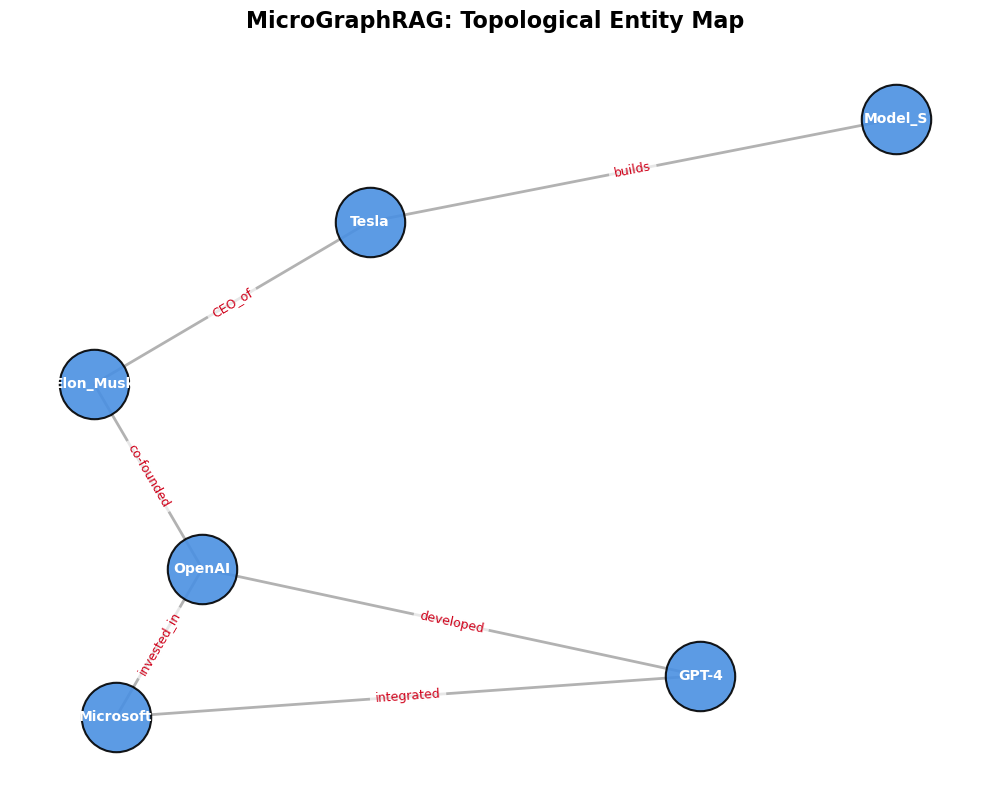

In [18]:
import matplotlib.pyplot as plt

def visualize_knowledge_graph(G: nx.Graph):
    """
    Projects the topological Knowledge Graph into a 2D space using a 
    force-directed spring layout and renders it via matplotlib.
    """
    if G.number_of_nodes() == 0:
        print("The graph is empty. Run extract_and_build_graph() first.")
        return

    # 1. Compute the 2D layout (Physics Simulation)
    # k controls the optimal distance between nodes. 
    # iterations dictates how long the "springs" are allowed to settle.
    pos = nx.spring_layout(G, k=0.8, iterations=50, seed=42)

    # 2. Initialize the canvas
    plt.figure(figsize=(10, 8), facecolor="white")

    # 3. Render Nodes
    nx.draw_networkx_nodes(
        G, pos, 
        node_color="#4A90E2", 
        node_size=2500, 
        edgecolors="black", 
        linewidths=1.5,
        alpha=0.9
    )

    # 4. Render Node Labels (The Entities)
    nx.draw_networkx_labels(
        G, pos, 
        font_size=10, 
        font_family="sans-serif", 
        font_weight="bold", 
        font_color="white"
    )

    # 5. Render Edges (The Connections)
    nx.draw_networkx_edges(
        G, pos, 
        width=2.0, 
        alpha=0.6, 
        edge_color="gray"
    )

    # 6. Render Edge Labels (The Relationships)
    # We must extract the 'relation' attribute we stored during graph construction
    edge_attributes = nx.get_edge_attributes(G, 'relation')
    nx.draw_networkx_edge_labels(
        G, pos, 
        edge_labels=edge_attributes, 
        font_color="#D0021B", 
        font_size=9,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.7)
    )

    # 7. Finalize and Display
    plt.title("MicroGraphRAG: Topological Entity Map", fontsize=16, fontweight="bold", pad=20)
    plt.axis("off") # Hide the x/y Cartesian axes
    plt.tight_layout()
    plt.show()

# ==========================================
# Execution in Notebook
# ==========================================
# Assuming `rag` has already been populated with triplets:
# rag.extract_and_build_graph(triplets)

visualize_knowledge_graph(rag.G)